connact drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

# ✏️ UBAH DI SINI kalau mau nama/lokasi folder lain
FOLDER = '/content/drive/MyDrive/Projek_PAW_Kelompok3'

FOLDER_RAW = os.path.join(FOLDER, 'tweets-data')   # hasil crawling mentah
FOLDER_OUT = os.path.join(FOLDER, 'output')        # hasil olahan
os.makedirs(FOLDER_RAW, exist_ok=True)
os.makedirs(FOLDER_OUT, exist_ok=True)

# Pindah ke folder proyek. tweet-harvest selalu menyimpan ke "tweets-data/" di folder kerja saat ini,
# jadi dengan pindah ke sini, hasil crawling otomatis masuk ke Drive.
os.chdir(FOLDER)
print('Folder kerja sekarang:', os.getcwd())

Mounted at /content/drive
Folder kerja sekarang: /content/drive/MyDrive/Projek_PAW_Kelompok3


In [ ]:
!npx -y playwright install-deps chromium

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴Installing dependencies...
Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:8 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [1,912 kB]
Hit:11 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages 

token x

In [ ]:
try:
    from google.colab import userdata
    X_AUTH_TOKEN = userdata.get('X_AUTH_TOKEN')
    print('Token diambil dari Secrets')
except Exception as e:
    print('Secrets belum bisa dibaca:', type(e).__name__)
    from getpass import getpass
    X_AUTH_TOKEN = getpass('Tempel auth_token X kamu lalu tekan Enter: ').strip()

print('Token terbaca ✅ (panjang', len(X_AUTH_TOKEN), 'karakter)')


Secrets belum bisa dibaca: SecretNotFoundError
Tempel auth_token X kamu lalu tekan Enter: ··········
Token terbaca ✅ (panjang 40 karakter)


CRAWL DATA

In [ ]:
# Klo ada yg mau disesuaikan nnti tinggal di ubah aja yak
KATA_KUNCI = [
    'ilustrator ai',
    'hak cipta ai',
    'seniman ai',
    'desainer ai',
    'penulis ai',
    'musisi ai',
]

LIMIT_PER_QUERY = 300
TAB = 'LATEST'              # 'LATEST' atau 'TOP'
CRAWL_DARI = None           # contoh: '01-01-2025'  (format DD-MM-YYYY), atau None
CRAWL_SAMPAI = None         # contoh: '11-10-2026', atau None
JEDA_ANTAR_QUERY = 60       # detik
VERSI_TWEET_HARVEST = '2.7.1'

print(f'{len(KATA_KUNCI)} query × {LIMIT_PER_QUERY} = target maksimal {len(KATA_KUNCI) * LIMIT_PER_QUERY} tweet mentah')

6 query × 300 = target maksimal 1800 tweet mentah


In [ ]:
import re, time, shlex

ULANG_SEMUA = False   # True = crawling ulang walaupun file sudah ada

def nama_file_query(kata_kunci):
    # contoh: 'hak cipta ai' -> 'hak_cipta_ai'
    return re.sub(r'[^a-z0-9]+', '_', kata_kunci.lower()).strip('_')

token_aman = shlex.quote(X_AUTH_TOKEN)

for i, kw in enumerate(KATA_KUNCI, start=1):
    nama = nama_file_query(kw)
    path_csv = os.path.join(FOLDER_RAW, nama + '.csv')

    if os.path.exists(path_csv) and not ULANG_SEMUA:
        print(f'[{i}/{len(KATA_KUNCI)}] "{kw}" sudah ada → dilewati')
        continue

    opsi_tanggal = ''
    if CRAWL_DARI:
        opsi_tanggal += ' --from ' + shlex.quote(CRAWL_DARI)
    if CRAWL_SAMPAI:
        opsi_tanggal += ' --to ' + shlex.quote(CRAWL_SAMPAI)

    kw_aman = shlex.quote(kw)
    print(f'\n[{i}/{len(KATA_KUNCI)}] Crawling "{kw}" → tweets-data/{nama}.csv')
    !npx -y tweet-harvest@{VERSI_TWEET_HARVEST} -o {nama} -s {kw_aman} --tab {TAB} -l {LIMIT_PER_QUERY} --token {token_aman} {opsi_tanggal}

    if i < len(KATA_KUNCI):
        print(f'Istirahat {JEDA_ANTAR_QUERY} detik sebelum query berikutnya...')
        time.sleep(JEDA_ANTAR_QUERY)

print('\nSelesai ✅')

[1/6] "ilustrator ai" sudah ada → dilewati
[2/6] "hak cipta ai" sudah ada → dilewati
[3/6] "seniman ai" sudah ada → dilewati
[4/6] "desainer ai" sudah ada → dilewati
[5/6] "penulis ai" sudah ada → dilewati
[6/6] "musisi ai" sudah ada → dilewati

Selesai ✅


cek hasil crawl mentah

In [4]:
import os, re, glob
import pandas as pd

file_mentah = sorted(f for f in glob.glob(os.path.join(FOLDER_RAW, '*.csv')) if not f.endswith('.old.csv'))

if not file_mentah:
    print('Belum ada file hasil crawling. Jalankan Langkah 1.2 dulu.')
else:
    ringkasan_mentah = pd.DataFrame(
        [{'file': os.path.basename(f), 'jumlah_tweet': len(pd.read_csv(f, dtype=str))} for f in file_mentah]
    )
    display(ringkasan_mentah)
    print('Total mentah (sebelum buang duplikat):', ringkasan_mentah['jumlah_tweet'].sum())

,file,jumlah_tweet
0,desainer_ai.csv,280
1,hak_cipta_ai.csv,300
2,ilustrator_ai.csv,300
3,musisi_ai.csv,240
4,penulis_ai.csv,300
5,seniman_ai.csv,300


Total mentah (sebelum buang duplikat): 1720


**Persiapan dan pembersihan data**

penggabungan semuua file

In [5]:
import os, re
import numpy as np
import pandas as pd

catatan_tahap = {}   # {nama tahap: {'Jumlah data': n, 'Keterangan': ...}}

def catat(tahap, data, keterangan=''):
    catatan_tahap[tahap] = {'Jumlah data': len(data), 'Keterangan': keterangan}
    print(f'✔ {tahap}: {len(data):,} baris')

daftar_df = []
for f in file_mentah:
    d = pd.read_csv(f, dtype={'id_str': str, 'conversation_id_str': str, 'user_id_str': str})
    d['query'] = os.path.basename(f).replace('.csv', '').replace('_', ' ')
    daftar_df.append(d)

df = pd.concat(daftar_df, ignore_index=True)
df = df.rename(columns={'id_str': 'id', 'full_text': 'text', 'favorite_count': 'like_count'})

kolom_wajib = ['id', 'text', 'like_count', 'created_at', 'lang']
kolom_kurang = [k for k in kolom_wajib if k not in df.columns]
if kolom_kurang:
    raise ValueError(f'Kolom {kolom_kurang} tidak ditemukan. Cek nama kolom di file mentah '
                     f'(mungkin versi tweet-harvest berbeda). Kolom yang ada: {list(df.columns)}')

# --- anonimisasi: buang kolom identitas & samarkan @mention ---
KOLOM_IDENTITAS = ['username', 'user_id_str', 'in_reply_to_screen_name', 'location', 'image_url']
df = df.drop(columns=[k for k in KOLOM_IDENTITAS if k in df.columns])
df['text'] = df['text'].fillna('').astype(str).str.replace(r'@\w+', '@user', regex=True)
# tiap mention tetap 1 token, jadi jumlah kata & hashtag tidak berubah

# --- waktu pengambilan (perkiraan dari waktu simpan file; cocokkan dengan catatan crawling kalian) ---
from datetime import datetime
waktu_ambil = [datetime.fromtimestamp(os.path.getmtime(f)) for f in file_mentah]
print('Waktu pengambilan:', min(waktu_ambil).strftime('%Y-%m-%d %H:%M'), 's.d.', max(waktu_ambil).strftime('%Y-%m-%d %H:%M'))

# simpan cadangan gabungan mentah (untuk arsip/laporan)
df.to_csv(os.path.join(FOLDER_OUT, 'data_mentah_gabungan.csv'), index=False)

catat('1. Data mentah (gabungan semua query)', df, f'{len(file_mentah)} file query')
print('\nKolom yang tersedia:', list(df.columns))
df.head()

Waktu pengambilan: 2026-10-11 19:14 s.d. 2026-10-11 19:44
✔ 1. Data mentah (gabungan semua query): 1,720 baris

Kolom yang tersedia: ['conversation_id_str', 'created_at', 'like_count', 'text', 'id', 'lang', 'quote_count', 'reply_count', 'retweet_count', 'tweet_url', 'query']


,conversation_id_str,created_at,like_count,text,id,lang,quote_count,reply_count,retweet_count,tweet_url,query
0,2109282915469218229,2026-10-11T14:00:10.000Z,1,ai bicho q situação realmente n eh coisa de mi...,2109282915469218229,pt,0,0,0,https://x.com/vicvaperobis/status/210928291546...,desainer ai
1,2108900580274172338,2026-10-10T13:25:04.000Z,0,eh dia bukan illustrator. dia itu desainer sa...,2108911694097580090,in,0,0,0,https://x.com/prodbyww/status/2108911694097580090,desainer ai
2,2108840512337727610,2026-10-10T08:44:56.000Z,0,*secepat AI \n\ngak fokus. desainer sekarang s...,2108841197997543902,in,0,0,0,https://x.com/hypermatrxx/status/2108841197997...,desainer ai
3,2108840512337727610,2026-10-10T08:42:13.000Z,0,dan juga company sekarang tau desainer itu gak...,2108840512337727610,in,0,2,0,https://x.com/hypermatrxx/status/2108840512337...,desainer ai
4,2108436727421661567,2026-10-09T05:57:43.000Z,0,3. Desainer \nkarena campaign awal mereka udah...,2108436727421661567,in,0,0,0,https://x.com/hannaaakkk/status/21084367274216...,desainer ai


buang duplikat berdasarkan ID tweet

In [6]:
sebelum = len(df)
df = df.drop_duplicates(subset='id', keep='first').reset_index(drop=True)
print('Duplikat dibuang:', sebelum - len(df))
catat('2. Buang duplikat', df, 'berdasarkan kolom id')

Duplikat dibuang: 34
✔ 2. Buang duplikat: 1,686 baris


saring bahasa

In [7]:
print('Sebaran kode bahasa (10 teratas):')
print(df['lang'].value_counts().head(10))

KODE_INDONESIA = ['in', 'id']   # 'in' = kode X untuk Bahasa Indonesia; 'id' hanya untuk jaga-jaga
df = df[df['lang'].isin(KODE_INDONESIA)].reset_index(drop=True)
catat('3. Saring bahasa', df, "lang = 'in' (Bahasa Indonesia)")

Sebaran kode bahasa (10 teratas):
lang
id     902
in     720
en      25
pt      21
es       5
ja       3
et       2
it       2
pl       2
zxx      1
Name: count, dtype: int64
✔ 3. Saring bahasa: 1,622 baris


saring periode

In [8]:
waktu = pd.to_datetime(df['created_at'], format='%a %b %d %H:%M:%S %z %Y', errors='coerce', utc=True)
if waktu.isna().all():
    # cadangan kalau formatnya berbeda / sel ini dijalankan ulang
    waktu = pd.to_datetime(df['created_at'], errors='coerce', utc=True)
df['created_at'] = waktu.dt.tz_convert('Asia/Jakarta')

print('Tanggal gagal dibaca :', df['created_at'].isna().sum())
print('Tweet paling awal    :', df['created_at'].min())
print('Tweet paling akhir   :', df['created_at'].max())
print('\nJumlah tweet per bulan:')
print(df['created_at'].dt.strftime('%Y-%m').value_counts().sort_index())

Tanggal gagal dibaca : 0
Tweet paling awal    : 2018-03-09 19:17:01+07:00
Tweet paling akhir   : 2026-10-11 23:05:59+07:00

Jumlah tweet per bulan:
created_at
2018-03      2
2018-06      2
2018-10      1
2019-04      1
2019-05      1
          ... 
2026-06    112
2026-07    106
2026-08    126
2026-09    101
2026-10     73
Name: count, Length: 67, dtype: int64


In [9]:
# periode (format YYYY-MM-DD, kedua tanggal ikut dihitung)
PERIODE_MULAI = '2025-01-01'
PERIODE_SELESAI = '2026-10-11'

mulai = pd.Timestamp(PERIODE_MULAI, tz='Asia/Jakarta')
selesai = pd.Timestamp(PERIODE_SELESAI, tz='Asia/Jakarta') + pd.Timedelta(days=1)   # +1 hari agar tanggal terakhir ikut penuh

# baris yang tanggalnya gagal dibaca (NaT) otomatis ikut terbuang di sini
df = df[(df['created_at'] >= mulai) & (df['created_at'] < selesai)].reset_index(drop=True)
catat('4. Saring periode', df, f'{PERIODE_MULAI} s.d. {PERIODE_SELESAI}')

✔ 4. Saring periode: 1,490 baris


saring relevansi topik

In [10]:
# kata kelompok AI (ditulis sebagai pola regex)
KATA_AI = [
    'ai', r'a\.i', 'kecerdasan buatan', 'artificial intelligence', 'genai', 'aiart',
    'midjourney', 'stable diffusion', 'dall[- ]?e', 'chatgpt', 'gpt', 'gemini',
    'copilot', 'suno', 'udio', 'sora',
]

# kata kelompok profesi/karya kreatif (ilustrasi, desain, penulisan, musik)
KATA_KREATIF = [
    'ilustrator', 'ilustrasi', 'illustrator', 'illustration', 'seniman', 'artist', 'art', 'seni',
    'karya', 'gambar', 'menggambar', 'lukisan', 'pelukis', 'drawing', 'fanart', 'animator', 'animasi',
    'komik', 'komikus', 'desainer', 'designer', 'desain', 'design', 'penulis', 'writer', 'tulisan',
    'menulis', 'novel', 'cerpen', 'puisi', 'copywriter', 'musisi', 'musik', 'music', 'lagu',
    'penyanyi', 'komposer', 'fotografer', 'fotografi', 'kreator', 'creator', 'kreatif', 'creative',
    'pengisi suara', 'voice actor',     'hak cipta', 'copyright', 'royalti', 'poster', 'logo', 'pekerja seni',
    'konten kreator', 'vokal', 'film', 'aktor', 'sutradara',
]

def buat_pola(daftar_kata):
    # \b(kata1|kata2|...)(nya|ku|mu)?\b  → cocok sebagai kata utuh, boleh berakhiran -nya/-ku/-mu
    return re.compile(r'\b(?:' + '|'.join(daftar_kata) + r')(?:nya|ku|mu)?\b', flags=re.IGNORECASE)

POLA_AI = buat_pola(KATA_AI)
POLA_KREATIF = buat_pola(KATA_KREATIF)

teks = df['text'].fillna('').astype(str)
ada_ai = teks.str.contains(POLA_AI)
ada_kreatif = teks.str.contains(POLA_KREATIF)
relevan = ada_ai & ada_kreatif

print('Memuat kata AI          :', ada_ai.sum())
print('Memuat kata kreatif     :', ada_kreatif.sum())
print('Memuat keduanya (lolos) :', relevan.sum())

dibuang = df[~relevan]
print('\nContoh tweet yang DIBUANG karena dianggap tidak relevan:')
for t in dibuang['text'].sample(min(5, len(dibuang)), random_state=1):
    print('-', str(t)[:200])

df = df[relevan].reset_index(drop=True)
catat('5. Saring relevansi', df, 'memuat kata AI dan kata profesi kreatif')

Memuat kata AI          : 1365
Memuat kata kreatif     : 1407
Memuat keduanya (lolos) : 1287

Contoh tweet yang DIBUANG karena dianggap tidak relevan:
- 35 Prompt AI untuk penulisan tugas akhir (skripsi, tesis, disertasi)
dan artikel jurnal ilmiah

- Prompt 1: Bantu himpun hasil-hasil penelitian tentang ... (sebutkan topik atau isu) yang paling mutakh
- Apa sih sulitnya bikin konten original ? 

gw kasih contoh bahan nya 👇

Tips biar ketek ga bau busuk 
Cara gw merubah 100k jadi 200k dalam sebulan 
Makan buah ini asam urat gw mendadak sembuh
Karena w
- Prompt-prompt ini dirancang untuk semua jenis freelancer kayak desainer, penulis, programmer, konsultan, virtual assistant, fotografer, dan lainnya.

Ganti semua [ ] dengan info dan konteks kalian yan
- @user ini kamu ya kak? mending gausah karna:

1. melanggar hak cipta
2. artisnya aja blm komersilin ini, masa km jualin duluan dgn desain yg sama?
3. ada dreamnya juga, sementara itu aslinya jaket ili
- Dokumen setebal 69 halaman dengan j

buang postingan promosi

In [11]:
FRASA_PROMOSI_KUAT = [   # hampir pasti iklan, berlaku juga untuk balasan
    'open order', 'open commission', 'open comm', 'comm open', 'commission open', 'slot open',
    r'wa\.me', 'link di bio', 'link in bio', 'cek bio', 'dm for order', 'terima jasa', 'menerima jasa',
]
FRASA_PROMOSI_LEMAH = [  # bisa muncul di diskusi biasa, hanya berlaku untuk non-balasan
    'promo', 'diskon', 'discount', 'giveaway', 'give away', 'voucher', 'gratis ongkir',
    'daftar sekarang', 'order sekarang', 'pesan sekarang', 'hubungi kami',
    'jasa desain', 'jasa ilustrasi', 'jasa pembuatan',
    'webinar', 'bootcamp', 'kelas online', 'free trial', 'affiliate', 'sponsored',
]
def pola_frasa(daftar):
    return re.compile(r'\b(?:' + '|'.join(daftar) + r')\b', flags=re.IGNORECASE)

teks = df['text'].fillna('').astype(str)
balasan = teks.str.startswith('@')
promosi = teks.str.contains(pola_frasa(FRASA_PROMOSI_KUAT)) | \
          (teks.str.contains(pola_frasa(FRASA_PROMOSI_LEMAH)) & ~balasan)

cocok = teks.str.extract(r'(?i)\b(' + '|'.join(FRASA_PROMOSI_KUAT + FRASA_PROMOSI_LEMAH) + r')\b')[0]
print('Terdeteksi promosi:', promosi.sum())
print(cocok[promosi].value_counts().to_dict())
for t in df.loc[promosi, 'text'].head(10):
    print('-', str(t)[:150].replace('\n', ' '))
df = df[~promosi].reset_index(drop=True)
catat('6. Buang promosi', df, 'frasa kuat (semua) + frasa lemah (non-balasan)')

Terdeteksi promosi: 1
{'Open Commission': 1}
- No AI. Ubah Fotomu menjadi sebuah ilustrasi istimewa. ✨🌻Open Commission Ilustrasi digital, Dm For Order 😁💪🕊️✨  #ilustrasidigital #illustrationㅤ #jasai
✔ 6. Buang promosi: 1,286 baris


buang teks kosong dan likes yang tidak valid

In [12]:
teks_kosong = df['text'].isna() | (df['text'].astype(str).str.strip() == '')
df = df[~teks_kosong].reset_index(drop=True)
catat('7. Buang teks kosong', df)

df['like_count'] = pd.to_numeric(df['like_count'], errors='coerce')
likes_tidak_valid = df['like_count'].isna() | (df['like_count'] < 0)
print('Likes tidak valid:', likes_tidak_valid.sum())
df = df[~likes_tidak_valid].reset_index(drop=True)
df['like_count'] = df['like_count'].astype(int)
catat('8. Buang likes tidak valid', df, 'kosong/bukan angka/negatif dibuang, tidak diganti 0')

✔ 7. Buang teks kosong: 1,286 baris
Likes tidak valid: 0
✔ 8. Buang likes tidak valid: 1,286 baris


bersihkan teks

In [13]:
import html

def bersihkan_teks(t):
    t = html.unescape(str(t))
    t = t.lower()
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)   # 3. tautan
    t = re.sub(r'@\w+', ' ', t)                     # 4. mention
    t = re.sub(r'\d+', ' ', t)                      # 5. angka
    t = re.sub(r'[^a-z\s]', ' ', t)                 # 6. simbol, tanda baca, emoji, '#'
    t = re.sub(r'\s+', ' ', t).strip()              # 7. spasi berlebih
    return t

df['text_clean'] = df['text'].apply(bersihkan_teks)

kosong_setelah_bersih = df['text_clean'].str.len() == 0
print('Kosong setelah dibersihkan:', kosong_setelah_bersih.sum())
df = df[~kosong_setelah_bersih].reset_index(drop=True)
catat('9. Buang yang kosong setelah dibersihkan', df)

print('\nContoh perbandingan:')
for _, r in df.sample(min(3, len(df)), random_state=0).iterrows():
    print('ASLI  :', r['text'][:200])
    print('BERSIH:', r['text_clean'][:200], '\n')

Kosong setelah dibersihkan: 0
✔ 9. Buang yang kosong setelah dibersihkan: 1,286 baris

Contoh perbandingan:
ASLI  : Kapan lagi brainstorming sama penulis Pasarampok langsung. Buat kawan-kawan penulis yang kemarin  hilang arah, daripada tanya AI mending brainstorming sama kak Arsyanendra. FYI, beliau ini juga salah 
BERSIH: kapan lagi brainstorming sama penulis pasarampok langsung buat kawan kawan penulis yang kemarin hilang arah daripada tanya ai mending brainstorming sama kak arsyanendra fyi beliau ini juga salah satu  

ASLI  : Di tengah gempuran AI, doi dan agensinya masih menghargai ilustrator🥺
BERSIH: di tengah gempuran ai doi dan agensinya masih menghargai ilustrator 

ASLI  : Ih aku seneng bgt ke temen2 ilustrator yg bisa memenuhi kefomoan ortu yg pengen AI tapi dibikinin ilustrasi otentik dg skill gambar mereka😊 awalnya mamahku jg fomo pake AI tapi skrg bangga anaknya ada
BERSIH: ih aku seneng bgt ke temen ilustrator yg bisa memenuhi kefomoan ortu yg pengen ai tapi dibikinin il

In [14]:
# (a) duplikat isi
dup_persis = df['text_clean'].duplicated(keep='first')
dup_mirip  = df['text_clean'].str[:80].duplicated(keep='first')
print('Duplikat persis:', dup_persis.sum(), '| mirip (80 karakter awal):', dup_mirip.sum())
for t in df.loc[dup_mirip, 'text'].head(5):
    print('-', t[:130].replace('\n', ' '))
df = df[~dup_mirip].reset_index(drop=True)
catat('10. Buang duplikat isi', df, 'text_clean sama / 80 karakter awal sama')

# (b) pemetaan id (jangan masuk ZIP) lalu id urut
pemetaan = pd.DataFrame({'id_tweet_asli': df['id']})
df['id'] = [f'P{i+1:04d}' for i in range(len(df))]
pemetaan['id'] = df['id']
pemetaan.to_csv(os.path.join(FOLDER_OUT, 'pemetaan_id_RAHASIA.csv'), index=False)

# (c) berkas audit relevansi: baca 30 postingan, isi kolom 'relevan' (1 = sesuai topik, 0 = tidak)
audit = df.sample(n=min(30, len(df)), random_state=7)[['id', 'text', 'query']].reset_index(drop=True)
audit['relevan'] = ''
audit.to_csv(os.path.join(FOLDER_OUT, 'audit_relevansi.csv'), index=False, encoding='utf-8-sig')
print(audit['query'].value_counts().to_dict())

Duplikat persis: 7 | mirip (80 karakter awal): 10
- AI Gantikan 83 Juta Pekerjaan, Profesi Desainer Grafis dan Akuntan Mulai Hilang 2030 https://t.co/fjR5VBPugm
- RUU Hak Cipta Mulai Dibahas: Aturan AI, Royalti Digital, dan Masa Depan Kreator Indonesia https://t.co/6izY2boUhT via @user
- @user @user Pertama, lu harus tau dulu alasan kenapa Artists benci AI.  Secara umum, AI itu mengambil data yang dikirimkan dan dis
- @user @user Btw di China aja banyak kok akun² begini, udah gak aneh malahan klo kontennya full AI dan followersnya emng banyak. So
- Tiga youtuber asal Amerika Serikat menggugat perusahaan induk Snapchat, Snap, atas dugaan pelanggaran hak cipta untuk melatih mode
✔ 10. Buang duplikat isi: 1,276 baris
{'penulis ai': 7, 'seniman ai': 6, 'ilustrator ai': 5, 'musisi ai': 5, 'desainer ai': 5, 'hak cipta ai': 2}


In [15]:
def baca_csv_excel(path, **kw):
    """Baca CSV hasil simpan Excel: tahan BOM dan pemisah ';' atau ','."""
    with open(path, encoding='utf-8-sig') as f:
        header = f.readline()
    sep = ';' if header.count(';') > header.count(',') else ','
    return pd.read_csv(path, sep=sep, encoding='utf-8-sig', **kw)

path_aud = os.path.join(FOLDER_OUT, 'audit_relevansi_terisi.csv')
assert os.path.exists(path_aud), 'Isi audit_relevansi.csv lalu simpan sebagai audit_relevansi_terisi.csv'
aud = baca_csv_excel(path_aud, dtype={'id': str})
aud.columns = aud.columns.str.strip().str.lower()
aud['relevan'] = pd.to_numeric(aud['relevan'], errors='coerce')
assert aud['relevan'].isin([0, 1]).all(), 'Kolom relevan harus berisi 1 atau 0 saja'

n_rel = int(aud['relevan'].sum())
print(f'Relevan: {n_rel} dari {len(aud)} ({n_rel/len(aud)*100:.0f}%)')
id_buang = aud.loc[aud['relevan'] == 0, 'id']
for t in aud.loc[aud['relevan'] == 0, 'text'].head(5):
    print('- tidak relevan:', t[:150].replace('\n', ' '))
df = df[~df['id'].isin(id_buang)].reset_index(drop=True)
catat('11. Buang tidak relevan (hasil audit)', df, f'{len(id_buang)} dari {len(aud)} sampel audit')

Relevan: 24 dari 30 (80%)
- tidak relevan: Desainer MinNeo masih libur lebaran, daripada pake foto AI, mending MinNeo bikin sendiri 🙏  Intinya mau ngabarin Sobat, kalo seluruh layanan @user ber
- tidak relevan: #SobatTelkom, inovasi, kolaborasi, hingga pemberdayaan jadi highlight Telkom pada minggu ini.   Mulai dari AI, digitalisasi layanan, hingga ruang bagi
- tidak relevan: Apa kalo Allah berfirman di Kejadian 1 itu kaya ngeprompt AI ya? sedangkan pas penciptaan manusia, Allah benar benar jadi ilustrator yang ngegambar ma
- tidak relevan: Karena kita sudah masuk Juli, mari kita Recap drama X Juni 2026 : 1. Yang udah putus tapi jadian lagi 2. Yang berkaitan dengan salah satu musisi indon
- tidak relevan: PEMBUATAN GAME FULL AI MAKIN NYATA CAPYBARA DELIVERY RAMPUNG DALAM 2 MINGGU  Seorang kreator dilaporkan berhasil mengembangkan game bertema capybara d
✔ 11. Buang tidak relevan (hasil audit): 1,270 baris


tabel jumlah data per tahap

In [16]:
tabel_tahap = pd.DataFrame.from_dict(catatan_tahap, orient='index').reset_index().rename(columns={'index': 'Tahap'})
tabel_tahap['Berkurang'] = (-tabel_tahap['Jumlah data'].diff()).fillna(0).astype(int)
tabel_tahap = tabel_tahap[['Tahap', 'Jumlah data', 'Berkurang', 'Keterangan']]
display(tabel_tahap)

tabel_tahap.to_csv(os.path.join(FOLDER_OUT, 'jumlah_data_per_tahap.csv'), index=False)

n_akhir = len(df)
if n_akhir >= 150:
    print(f'Data akhir {n_akhir} postingan — memenuhi target minimal 150.')
else:
    print(f'Data akhir baru {n_akhir} postingan (kurang dari 150). Tambah kata kunci atau naikkan LIMIT_PER_QUERY '
          'di Langkah 1.1, jalankan lagi Langkah 1.2 (query lama otomatis dilewati), lalu ulangi Bagian 2.')

,Tahap,Jumlah data,Berkurang,Keterangan
0,1. Data mentah (gabungan semua query),1720,0,6 file query
1,2. Buang duplikat,1686,34,berdasarkan kolom id
2,3. Saring bahasa,1622,64,lang = 'in' (Bahasa Indonesia)
3,4. Saring periode,1490,132,2025-01-01 s.d. 2026-10-11
4,5. Saring relevansi,1287,203,memuat kata AI dan kata profesi kreatif
5,6. Buang promosi,1286,1,frasa kuat (semua) + frasa lemah (non-balasan)
6,7. Buang teks kosong,1286,0,
7,8. Buang likes tidak valid,1286,0,"kosong/bukan angka/negatif dibuang, tidak diga..."
8,9. Buang yang kosong setelah dibersihkan,1286,0,
9,10. Buang duplikat isi,1276,10,text_clean sama / 80 karakter awal sama


Data akhir 1270 postingan — memenuhi target minimal 150.


simpan dataset final

In [17]:
KOLOM_FINAL = ['id', 'created_at', 'text', 'text_clean', 'like_count',
               'retweet_count', 'reply_count', 'lang', 'query', 'tweet_url']
KOLOM_FINAL = [k for k in KOLOM_FINAL if k in df.columns]   # jaga-jaga kalau ada kolom yang tidak tersedia

df_final = df[KOLOM_FINAL].copy()
path_final = os.path.join(FOLDER_OUT, 'dataset_final.csv')
df_final.to_csv(path_final, index=False, encoding='utf-8')

print('Tersimpan di:', path_final)
print('Ukuran (baris, kolom):', df_final.shape)
df_final.head()

Tersimpan di: /content/drive/MyDrive/Projek_PAW_Kelompok3/output/dataset_final.csv
Ukuran (baris, kolom): (1270, 10)


,id,created_at,text,text_clean,like_count,retweet_count,reply_count,lang,query,tweet_url
0,P0001,2026-10-10 20:25:04+07:00,eh dia bukan illustrator. dia itu desainer sa...,eh dia bukan illustrator dia itu desainer sama...,0,0,0,in,desainer ai,https://x.com/prodbyww/status/2108911694097580090
1,P0002,2026-10-10 15:44:56+07:00,*secepat AI \n\ngak fokus. desainer sekarang s...,secepat ai gak fokus desainer sekarang saingan...,0,0,0,in,desainer ai,https://x.com/hypermatrxx/status/2108841197997...
2,P0003,2026-10-10 15:42:13+07:00,dan juga company sekarang tau desainer itu gak...,dan juga company sekarang tau desainer itu gak...,0,0,2,in,desainer ai,https://x.com/hypermatrxx/status/2108840512337...
3,P0004,2026-10-09 12:57:43+07:00,3. Desainer \nkarena campaign awal mereka udah...,desainer karena campaign awal mereka udah serb...,0,0,0,in,desainer ai,https://x.com/hannaaakkk/status/21084367274216...
4,P0005,2026-10-08 23:25:17+07:00,ironisnya di dunia yg kt dituntut kerja kerja ...,ironisnya di dunia yg kt dituntut kerja kerja ...,0,0,0,in,desainer ai,https://x.com/Lilcardamon/status/2108232272281...


In [18]:
from google.colab import files
files.download(path_final)
files.download(os.path.join(FOLDER_OUT, 'jumlah_data_per_tahap.csv'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**uji coba analisis**

muat dataset final

In [19]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if 'FOLDER_OUT' not in globals():          # runtime baru → sambungkan Drive lagi
    from google.colab import drive
    drive.mount('/content/drive')
    FOLDER = '/content/drive/MyDrive/Projek_PAW_Kelompok3'   # ✏️ samakan dengan Langkah 0.1
    FOLDER_OUT = os.path.join(FOLDER, 'output')

df = pd.read_csv(os.path.join(FOLDER_OUT, 'dataset_final.csv'), dtype={'id': str})

kolom_wajib = ['text', 'text_clean', 'created_at', 'like_count']
kolom_kurang = [k for k in kolom_wajib if k not in df.columns]
assert not kolom_kurang, f'Kolom wajib tidak ada: {kolom_kurang}'

# gaya grafik: garis tepi atas/kanan dihilangkan, grid tipis
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 110})
WARNA_SENTIMEN = {'positif': '#2a78d6', 'netral': '#a3a29c', 'negatif': '#e34948'}
WARNA_CLUSTER = ['#2a78d6', '#eb6834', '#1baf7a']
URUTAN_SENTIMEN = ['positif', 'netral', 'negatif']

print('Dataset dimuat ✅  ukuran:', df.shape)
df.head(3)

Dataset dimuat ✅  ukuran: (1270, 10)


,id,created_at,text,text_clean,like_count,retweet_count,reply_count,lang,query,tweet_url
0,P0001,2026-10-10 20:25:04+07:00,eh dia bukan illustrator. dia itu desainer sa...,eh dia bukan illustrator dia itu desainer sama...,0,0,0,in,desainer ai,https://x.com/prodbyww/status/2108911694097580090
1,P0002,2026-10-10 15:44:56+07:00,*secepat AI \n\ngak fokus. desainer sekarang s...,secepat ai gak fokus desainer sekarang saingan...,0,0,0,in,desainer ai,https://x.com/hypermatrxx/status/2108841197997...
2,P0003,2026-10-10 15:42:13+07:00,dan juga company sekarang tau desainer itu gak...,dan juga company sekarang tau desainer itu gak...,0,0,2,in,desainer ai,https://x.com/hypermatrxx/status/2108840512337...


siapkan sampel (disini aku pake nya 20)

In [20]:
sampel = df.sample(n=20, random_state=42)[['id', 'text']].reset_index(drop=True)
sampel.insert(0, 'no', range(1, len(sampel) + 1))
sampel['label_manual'] = ''

path_sampel = os.path.join(FOLDER_OUT, 'sampel_label_manual.csv')
sampel.to_csv(path_sampel, index=False)
print('Sampel disimpan di:', path_sampel)

try:
    from google.colab import files
    files.download(path_sampel)
except Exception:
    pass

sampel

Sampel disimpan di: /content/drive/MyDrive/Projek_PAW_Kelompok3/output/sampel_label_manual.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,no,id,text,label_manual
0,1,P1221,"lo kalo seniman (either musisi, poet, aktris, ...",
1,2,P1168,Suara sebagus ini ada yg edit2 pakai AI &amp;...,
2,3,P0425,"@user Pakai AI ya? 🤮\n\nPak, Buk, semua game d...",
3,4,P0983,Aku lebih milih baca cerita penulis yg typo sa...,
4,5,P0800,"gue akan simak terus diskusi ini, semoga gak k...",
5,6,P0792,@user di semarang poster ngajak buat bayar roy...,
6,7,P0024,Topeng ini bukan cosplay Cyberpunk. Ini senjat...,
7,8,P0408,Disney hingga Warner Bros Gugat MiniMax Tiongk...,
8,9,P0044,Kesempatan berkarir…!!\nAda 06 Info loker Jogj...,
9,10,P0586,"ini mungkin baru beberapa ilustrator, bisa aja...",


analisis sentimen dengan indoBERT

In [21]:
import torch
from transformers import pipeline

MODEL_SENTIMEN = 'mdhugol/indonesia-bert-sentiment-classification'
LABEL_MAP = {'LABEL_0': 'positif', 'LABEL_1': 'netral', 'LABEL_2': 'negatif'}

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Memakai', 'GPU' if device == 'cuda' else 'CPU')

klasifikasi = pipeline('text-classification', model=MODEL_SENTIMEN, tokenizer=MODEL_SENTIMEN, device=device)

hasil = klasifikasi(df['text'].astype(str).tolist(), batch_size=32, truncation=True, max_length=128)
df['sentimen'] = [LABEL_MAP.get(h['label'], h['label']) for h in hasil]
df['skor_sentimen'] = [round(h['score'], 4) for h in hasil]

df[['text', 'sentimen', 'skor_sentimen']].head(10)

Memakai GPU


config.json:   0%|          | 0.00/1.17k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  498MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  498MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/229k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,text,sentimen,skor_sentimen
0,eh dia bukan illustrator. dia itu desainer sa...,negatif,0.5124
1,*secepat AI \n\ngak fokus. desainer sekarang s...,negatif,0.9923
2,dan juga company sekarang tau desainer itu gak...,negatif,0.9908
3,3. Desainer \nkarena campaign awal mereka udah...,negatif,0.9975
4,ironisnya di dunia yg kt dituntut kerja kerja ...,negatif,0.9823
5,"My take, kalo bikin seni pake AI sekalipun gak...",negatif,0.9326
6,ini yg gue rasain hari ini :( benci bgt sama t...,negatif,0.9947
7,"@user Dari segi speed of delivery, breadth, de...",negatif,0.7780
8,@user READY TO HELP KAKK start 150k design ful...,netral,0.9096
9,"SMA-ku kekurangan desainer grafis, kah? Sampai...",negatif,0.7544


,jumlah,persen
sentimen,,
positif,177,13.9
netral,365,28.7
negatif,728,57.3


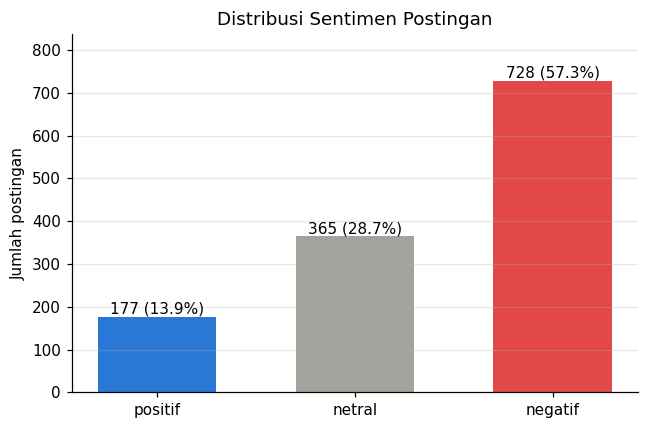


Contoh tiap sentimen:

[POSITIF]
  - 🔥 Ini rugi kalau lu ga save! 
nemu kumpulan 10 skill yang bisa bikin Claude naik level dari sekadar chatbot jadi partner kerja yang jauh lebih powerful. 🤯

Mulai dari bikin website, desain, debugging,
  - @user mantap kak
bagaimana perkembagnan desainer di era ai ini kak?

desain buku tetap indesign paling bagus ya kak?

[NETRAL]
  - @user READY TO HELP KAKK start 150k design full ilust no ai dijamin sesuai request dan desainer enak diajak diskusi! langsung wa ajaa https://t.co/wuyzNdoEW8
  - @user Kayaknya kalo desain ga mungkin full ai, karna ini 3D.
Tp zaman sekarang software desainer emg udh pake fitur AI utk mempermudah.

[NEGATIF]
  - eh dia bukan illustrator. dia itu desainer  sama komikus (sesuai di bio IG dia). dia dulu beneran buat komik cerita muslim/ muslimah. entah kenapa sekarang semua desain  dia pake AI  dan buat video ce
  - *secepat AI 

gak fokus. desainer sekarang saingannya sama AI dan selera company. antara nurut sama korpo at

In [22]:
distribusi = df['sentimen'].value_counts().reindex(URUTAN_SENTIMEN, fill_value=0)
tabel_sentimen = pd.DataFrame({'jumlah': distribusi,
                               'persen': (distribusi / distribusi.sum() * 100).round(1)})
display(tabel_sentimen)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(distribusi.index, distribusi.values, width=0.6,
       color=[WARNA_SENTIMEN[s] for s in distribusi.index])
for i, s in enumerate(distribusi.index):
    ax.text(i, distribusi[s], f"{distribusi[s]} ({tabel_sentimen.loc[s, 'persen']}%)",
            ha='center', va='bottom', fontsize=10)
ax.set_title('Distribusi Sentimen Postingan')
ax.set_ylabel('Jumlah postingan')
ax.set_ylim(0, max(distribusi.max(), 1) * 1.15)   # ruang untuk label di atas batang
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('\nContoh tiap sentimen:')
for s in URUTAN_SENTIMEN:
    contoh = df[df['sentimen'] == s]
    print(f'\n[{s.upper()}]')
    for t in contoh['text'].head(2):
        print('  -', str(t)[:200])

df.to_csv(os.path.join(FOLDER_OUT, 'hasil_sentimen.csv'), index=False)

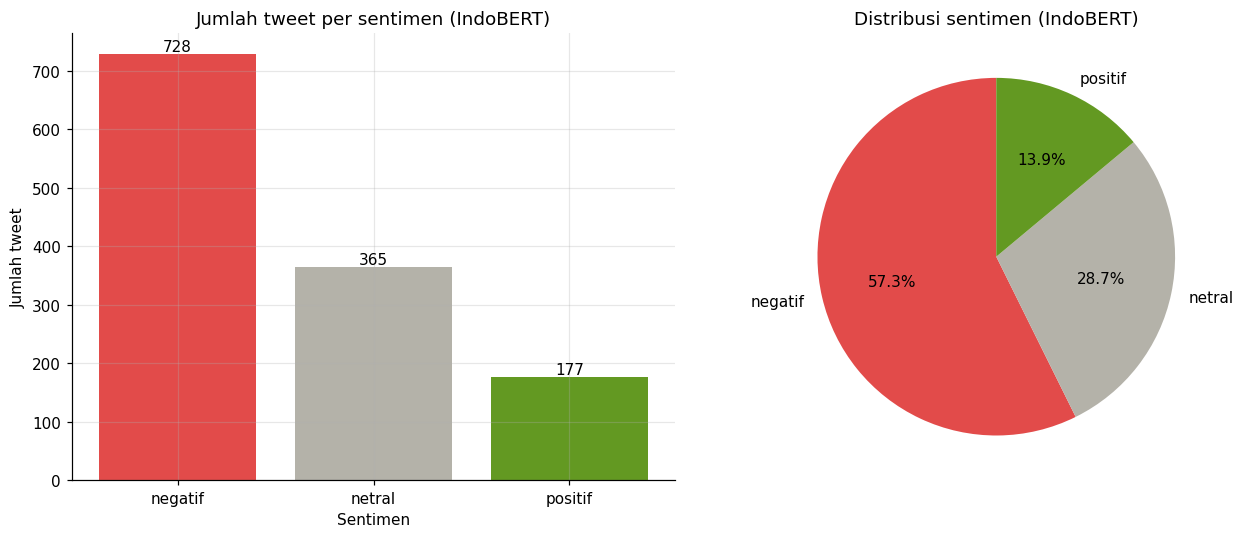

sentimen
negatif    728
netral     365
positif    177
Name: count, dtype: int64


In [23]:
import matplotlib.pyplot as plt

WARNA = {'negatif': '#E24B4A', 'netral': '#B4B2A9', 'positif': '#639922'}
URUTAN = ['negatif', 'netral', 'positif']

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

hitung = df['sentimen'].value_counts().reindex(URUTAN, fill_value=0)

# Kiri: jumlah tweet per sentimen (IndoBERT)
batang = ax[0].bar(hitung.index, hitung.values, color=[WARNA[s] for s in hitung.index])
ax[0].bar_label(batang)   # angka di atas batang
ax[0].set_title('Jumlah tweet per sentimen (IndoBERT)')
ax[0].set_xlabel('Sentimen')
ax[0].set_ylabel('Jumlah tweet')

# Kanan: persentase sentimen
ax[1].pie(hitung, labels=hitung.index, autopct='%1.1f%%',
          colors=[WARNA[s] for s in hitung.index], startangle=90)
ax[1].set_title('Distribusi sentimen (IndoBERT)')

plt.tight_layout()
plt.show()

print(hitung)

EVALUASI TERBATAS

In [24]:
path_terisi = os.path.join(FOLDER_OUT, 'sampel_label_manual_terisi.csv')
terisi = pd.read_csv(path_terisi, sep=None, engine='python', dtype={'id': str})
terisi.columns = terisi.columns.str.strip().str.lower()

NORMALISASI = {'positive': 'positif', 'pos': 'positif', 'negative': 'negatif',
               'neg': 'negatif', 'neutral': 'netral', 'net': 'netral'}
terisi['label_manual'] = terisi['label_manual'].astype(str).str.strip().str.lower().replace(NORMALISASI)

evaluasi = (terisi[['no', 'id', 'label_manual']]
            .merge(df[['id', 'text', 'sentimen', 'skor_sentimen']], on='id', how='left')
            .rename(columns={'sentimen': 'prediksi_model'}))

if evaluasi['text'].isna().any():
    print('⚠️ Ada id sampel yang tidak ada di dataset: dataset berubah setelah sampel dibuat. Buat ulang sampel dan labeli lagi.')
salah = ~evaluasi['label_manual'].isin(URUTAN_SENTIMEN)
if salah.any():
    print('⚠️ Label manual kosong/salah ketik pada no:', evaluasi.loc[salah, 'no'].tolist())

evaluasi['sesuai'] = evaluasi['label_manual'] == evaluasi['prediksi_model']
n_sesuai = int(evaluasi['sesuai'].sum()); persen_sesuai = n_sesuai / len(evaluasi) * 100

def wilson(k, n, z=1.96):
    p = k / n; pen = 1 + z**2 / n
    pusat = (p + z**2 / (2*n)) / pen
    sel = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / pen
    return pusat - sel, pusat + sel

lo, hi = wilson(n_sesuai, len(evaluasi))
print(f'Sesuai: {n_sesuai} dari {len(evaluasi)} ({persen_sesuai:.0f}%) | interval 95%: {lo*100:.0f}% - {hi*100:.0f}%')
print('Rata-rata skor | sesuai:', evaluasi.loc[evaluasi.sesuai, 'skor_sentimen'].mean().round(3),
      '| tidak sesuai:', evaluasi.loc[~evaluasi.sesuai, 'skor_sentimen'].mean().round(3))
display(pd.crosstab(evaluasi['label_manual'], evaluasi['prediksi_model']))

print('\nContoh ketidaksesuaian (yang model paling yakin tapi berbeda dari label manual):')
for _, r in evaluasi[~evaluasi['sesuai']].sort_values('skor_sentimen', ascending=False).head(3).iterrows():
    print(f"- [no {r['no']}] manual: {r['label_manual']} | model: {r['prediksi_model']} ({r['skor_sentimen']})")
    print('   ', str(r['text'])[:250].replace('\n', ' '))

evaluasi[['no', 'id', 'text', 'label_manual', 'prediksi_model', 'skor_sentimen', 'sesuai']] \
    .to_csv(os.path.join(FOLDER_OUT, 'evaluasi_sentimen.csv'), index=False)

Sesuai: 15 dari 20 (75%) | interval 95%: 53% - 89%
Rata-rata skor | sesuai: 0.956 | tidak sesuai: 0.814


prediksi_model,negatif,netral,positif
label_manual,,,
negatif,13,1,0
netral,1,2,2
positif,1,0,0



Contoh ketidaksesuaian (yang model paling yakin tapi berbeda dari label manual):
- [no 17] manual: netral | model: positif (0.9748)
    @user @user freepik ngga semuanya AI Kak, ada hasil ilustrator juga, toh dari jaman dulu kebanyakan designer graphic pakai website kaya gini dan fine aja, kalau kaka carinya AI ya dapatnya AI, tergantung keyword, lisensinya juga ngga murah tapi masih
- [no 14] manual: netral | model: negatif (0.9615)
    @user Sebagai tools alias alat bantu, AI itu bukan hal gak boleh dipakai. Depends on situations, untuk hasil karya karsa manusia tentu itu menyalahi aturan hak cipta dan sebenernya literasi AI juga udah ada aturannya, batasannya bahkan sampai soal ba
- [no 5] manual: netral | model: positif (0.8754)
    gue akan simak terus diskusi ini, semoga gak kelewat sih. semuanya please lebih bijak diskusinya. ini para penulis dan penikmat yang awam di bidang ini tapi against ai ikut nyimak


Clustering: TF-IDF + K-Means (K = 3)

In [25]:
import nltk
try:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOPWORDS_NLTK = stopwords.words('indonesian')
except Exception as e:
    print('Gagal mengunduh stopwords NLTK, hanya memakai daftar tambahan:', e)
    STOPWORDS_NLTK = []

# ✏️ UBAH DI SINI — kata topik + bahasa gaul/singkatan yang sering muncul di X
STOPWORDS_TAMBAHAN = [
    # kata topik (muncul di hampir semua postingan)
    'ai', 'artificial', 'intelligence', 'kecerdasan', 'buatan',
    # kata sambung umum (sudah ada di NLTK; ditulis ulang sebagai cadangan kalau NLTK gagal diunduh)
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan', 'untuk', 'karena', 'juga', 'tapi',
    'kalau', 'akan', 'atau', 'tidak', 'bisa', 'ada', 'jadi', 'sama', 'buat', 'pakai', 'gara',
    # singkatan & bahasa gaul
    'yg', 'ga', 'gak', 'nggak', 'ngga', 'enggak', 'gk', 'tdk', 'aja', 'udah', 'udh', 'dah',
    'sih', 'deh', 'dong', 'kok', 'nih', 'tuh', 'lho', 'loh', 'wkwk', 'wkwkwk', 'haha', 'hahaha',
    'kalo', 'klo', 'tp', 'dgn', 'utk', 'bgt', 'banget', 'jg', 'gw', 'gue', 'gua', 'lu', 'lo', 'elo',
    'km', 'nya', 'emang', 'gitu', 'gini', 'kayak', 'kaya', 'kek', 'pake', 'bikin', 'org', 'orang',
    # kata bahasa Inggris yang umum
    'the', 'and', 'to', 'of', 'is', 'in', 'it', 'for', 'this', 'that', 'you', 'with', 'are', 'not',
]
STOPWORDS = sorted(set(STOPWORDS_NLTK) | set(STOPWORDS_TAMBAHAN))
print('Jumlah stopwords:', len(STOPWORDS))

# kata kunci crawling: hanya dibuang dari word cloud (clustering tetap memakai STOPWORDS di atas)
KATA_KUNCI_WORDCLOUD = ['hak', 'cipta', 'desainer', 'ilustrator', 'seniman', 'penulis', 'musisi']
STOPWORDS_WORDCLOUD = sorted(set(STOPWORDS) | set(KATA_KUNCI_WORDCLOUD))
print('Stopwords khusus word cloud:', len(STOPWORDS_WORDCLOUD))

Jumlah stopwords: 825
Stopwords khusus word cloud: 832


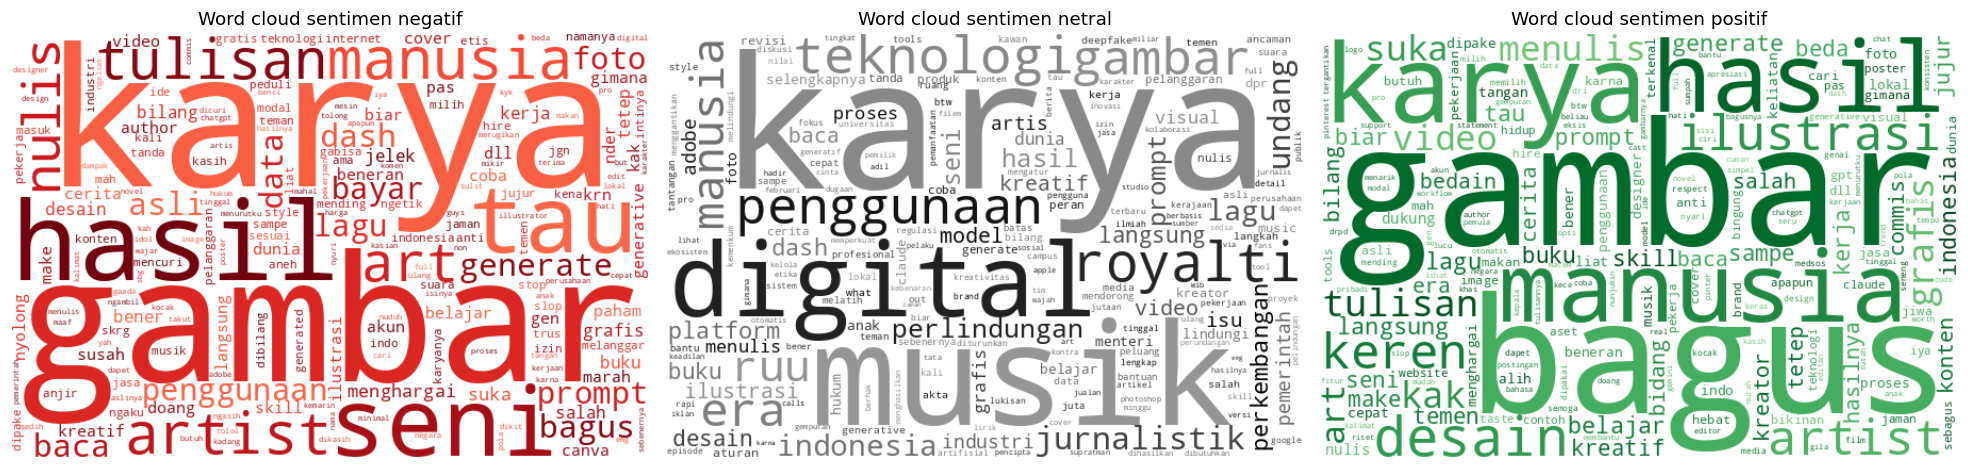

In [26]:
# Word cloud untuk setiap sentimen
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud
from matplotlib.colors import LinearSegmentedColormap

URUTAN = ['negatif', 'netral', 'positif']

def cmap_gelap(nama):
    # pakai setengah bagian gelap colormap agar kata terbaca
    warna = plt.get_cmap(nama)(np.linspace(0.5, 1, 256))
    return LinearSegmentedColormap.from_list(nama, warna)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
peta_warna = {'negatif': 'Reds', 'netral': 'Greys', 'positif': 'Greens'}

for i, s in enumerate(URUTAN):
    kata = ' '.join(df.loc[df['sentimen'] == s, 'text_clean'].fillna('')).split()
    kata = [w for w in kata if w not in STOPWORDS_WORDCLOUD and len(w) >= 3]  # buang stopwords & kata pendek
    if kata:
        wc = WordCloud(width=600, height=400, background_color='white',
                       colormap=cmap_gelap(peta_warna[s]))
        wc = wc.generate_from_frequencies(Counter(kata))
        ax[i].imshow(wc, interpolation='bilinear')
    else:
        ax[i].text(0.5, 0.5, 'Tidak ada tweet', ha='center', va='center')
    ax[i].set_title(f'Word cloud sentimen {s}')
    ax[i].axis('off')

plt.tight_layout()
plt.show()

Silhouette score

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

KATA_QUERY = ['penulis', 'seniman', 'ilustrator', 'musisi', 'desainer', 'hak', 'cipta']
BUANG_KATA_QUERY = False      # jalankan False dulu, lalu True, bandingkan hasilnya

stop_cluster = set(STOPWORDS) | (set(KATA_QUERY) if BUANG_KATA_QUERY else set())
stop_cluster = sorted(w for w in stop_cluster if re.fullmatch(r'[a-z]{3,}', w))  # selaras dengan token_pattern

vectorizer = TfidfVectorizer(stop_words=stop_cluster, token_pattern=r'(?u)\b[a-z]{3,}\b',
                             min_df=2, max_df=0.9)
X_tfidf = vectorizer.fit_transform(df['text_clean'].fillna(''))
kata_fitur = vectorizer.get_feature_names_out()
print('Ukuran matriks TF-IDF:', X_tfidf.shape, '→ (jumlah postingan, jumlah kata unik)')

tanpa_kata = int((X_tfidf.getnnz(axis=1) == 0).sum())
if tanpa_kata:
    print(f'Catatan: {tanpa_kata} postingan tidak punya kata tersisa setelah stopwords dibuang.')

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_tfidf)

print('\nJumlah postingan per cluster:')
print(df['cluster'].value_counts().sort_index())

sil = silhouette_score(X_tfidf, df['cluster'], metric='cosine')
print(f'\nSilhouette score: {sil:.3f}')

print('\nSebaran cluster per kata kunci crawling (% per cluster):')
display((pd.crosstab(df['cluster'], df['query'], normalize='index') * 100).round(0))

Ukuran matriks TF-IDF: (1270, 2436) → (jumlah postingan, jumlah kata unik)

Jumlah postingan per cluster:
cluster
0    229
1    561
2    480
Name: count, dtype: int64

Silhouette score: 0.018

Sebaran cluster per kata kunci crawling (% per cluster):


query,desainer ai,hak cipta ai,ilustrator ai,musisi ai,penulis ai,seniman ai
cluster,,,,,,
0,0.0,95.0,1.0,1.0,0.0,3.0
1,34.0,4.0,1.0,15.0,1.0,45.0
2,1.0,0.0,51.0,0.0,46.0,1.0


In [28]:
pusat = kmeans.cluster_centers_
jarak = kmeans.transform(X_tfidf)   # jarak setiap postingan ke setiap pusat cluster
ada_kata = X_tfidf.getnnz(axis=1) > 0   # postingan yang masih punya kata setelah stopwords dibuang

ringkasan_cluster = []
for c in range(3):
    top5 = [kata_fitur[i] for i in pusat[c].argsort()[::-1][:5]]
    semua = np.where(df['cluster'].values == c)[0]                    # seluruh anggota cluster
    anggota = np.where((df['cluster'].values == c) & ada_kata)[0]     # anggota yang punya kata (untuk contoh)
    terdekat = anggota[np.argsort(jarak[anggota, c])[:3]]

    ringkasan_cluster.append({'cluster': c, 'jumlah_postingan': len(semua),
                              'lima_kata_dominan': ', '.join(top5)})

    print(f'================ CLUSTER {c}  ({len(semua)} postingan) ================')
    print('5 kata dominan:', ', '.join(top5))
    print('3 contoh postingan paling mewakili:')
    for idx in terdekat:
        print('  -', str(df.loc[idx, 'text'])[:250])
    print()

ringkasan_cluster = pd.DataFrame(ringkasan_cluster)

================ CLUSTER 0  (229 postingan) ================
5 kata dominan: hak, cipta, karya, pelanggaran, ruu
3 contoh postingan paling mewakili:
  - 🚨BERITASATU THREAD - AI, ROYALTI, HINGGA KARYA JURNALISTIK MASUK RUU HAK CIPTA

Karya buatan AI bisa dilindungi hak cipta? Bagaimana kalau karya jurnalistik digunakan platform digital tanpa kejelasan hak ekonominya? Dua isu ini ikut dibahas dalam RUU
  - #Infografik Bolehkah pemilik hak cipta halang AI guna karya mereka? https://t.co/iWN6v2o91V
  - Karya AI bisa dapetin Hak Cipta?!

Beberapa waktu lalu Mahkamah Agung Amerika Serikat menolak buat meninjau kasus tentang "apakah karya AI bisa dapetin hak cipta?", sehingga sampai sekarang di mata hukum AS karya yang bisa dapetin hak cipta dan diaku

================ CLUSTER 1  (561 postingan) ================
5 kata dominan: seniman, desainer, musisi, karya, gambar
3 contoh postingan paling mewakili:
  - @user Ada yang bilang 'seniman' ai gue tonjok ye, seniman mana ada modal prompt doang


PENAMAAN CLUSTER

In [29]:
for c in range(3):
    sub = df[df['cluster'] == c]
    print(f'===== CLUSTER {c} ({len(sub)} postingan) - contoh acak =====')
    for t in sub.sample(min(8, len(sub)), random_state=1)['text']:
        print('-', t[:200].replace('\n', ' '))

===== CLUSTER 0 (229 postingan) - contoh acak =====
- Panja AI BKSAP DPR Kaji Hak Cipta Karya AI, Nila Yani Hardiyanti Dorong Regulasi Nasional yang Adil www.​gesuri.​id/pemerintahan/panja-ai-bksap-dpr-kaji-hak-cipta-karya-ai-nila-yani-hardiyanti-dorong-
- Tak payah nak kata effort sangat buat lukisan atau video guna AI generate apps.. sekadar prompt dan kalau ada orang curi kau punya hasil pun tak dikira hak cipta.. bukan sebagai karya..
- @user asistennya cheng lei bahkan ngasih footage syuting adegan stunt double yg itu hak cipta produksi drama (dan bisa digugat hukum lho kalo bocor) ke group chat haternya lulu buat digoreng dan dikas
- Buset adeknya Sam Altman ngetweet beginian   Jadi inget mantan karyawan OpenAI Sachir Balaji yg tiba2 “bundir”. Dia adalah  whistleblower dan saksi kunci di kasus pelanggaran hak cipta OpenAI/ChatGPT 
- Apple Digugat karena Dugaan Pelanggaran Hak Cipta dan AI https://t.co/l2pkiz1q8U
- @user Edukasi tentang hak cipta di Indo masih jelek banget emang, 

In [30]:
NAMA_TEMA = {
    0: 'Hak Cipta, Regulasi, dan Hukum terkait AI',
    1: 'Dampak AI bagi Seniman, Musisi, dan Desainer: Kritik dan Kekhawatiran',
    2: 'Tuduhan dan Deteksi Karya Buatan AI pada Penulis dan Ilustrator',
}
df['tema'] = df['cluster'].map(NAMA_TEMA)
ringkasan_cluster['tema'] = ringkasan_cluster['cluster'].map(NAMA_TEMA)
display(ringkasan_cluster)

,cluster,jumlah_postingan,lima_kata_dominan,tema
0,0,229,"hak, cipta, karya, pelanggaran, ruu","Hak Cipta, Regulasi, dan Hukum terkait AI"
1,1,561,"seniman, desainer, musisi, karya, gambar","Dampak AI bagi Seniman, Musisi, dan Desainer: ..."
2,2,480,"ilustrator, penulis, gambar, dash, tulisan",Tuduhan dan Deteksi Karya Buatan AI pada Penul...


Kata dominan (10 teratas) yang dimiliki bersama:
  cluster 0 & 1: karya
  cluster 0 & 2: -
  cluster 1 & 2: gambar

Sebaran sentimen per tema (% per baris):


sentimen,positif,netral,negatif
tema,,,
"Dampak AI bagi Seniman, Musisi, dan Desainer: Kritik dan Kekhawatiran",15.5,27.3,57.2
"Hak Cipta, Regulasi, dan Hukum terkait AI",3.5,49.3,47.2
Tuduhan dan Deteksi Karya Buatan AI pada Penulis dan Ilustrator,17.1,20.6,62.3


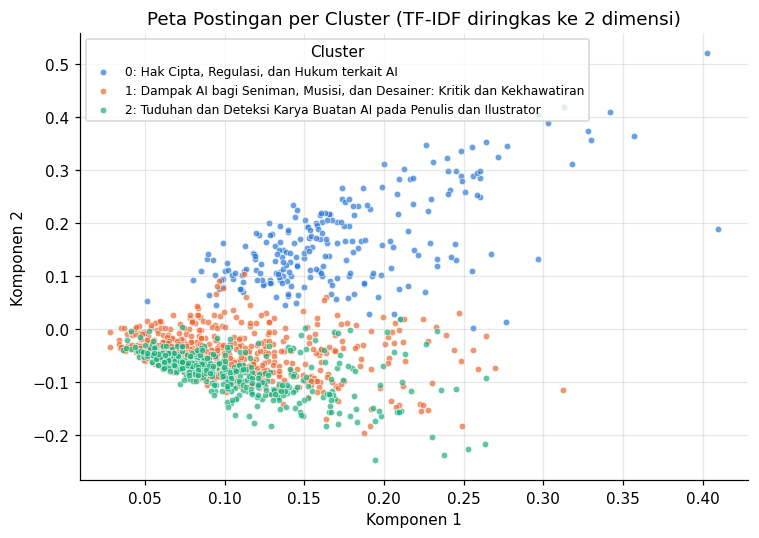

In [31]:
top10 = {c: set(kata_fitur[i] for i in pusat[c].argsort()[::-1][:10]) for c in range(3)}
print('Kata dominan (10 teratas) yang dimiliki bersama:')
for a, b in [(0, 1), (0, 2), (1, 2)]:
    bersama = sorted(top10[a] & top10[b])
    print(f'  cluster {a} & {b}:', ', '.join(bersama) if bersama else '-')

if 'sentimen' in df.columns:
    print('\nSebaran sentimen per tema (% per baris):')
    tabel_silang = pd.crosstab(df['tema'], df['sentimen'], normalize='index') * 100
    display(tabel_silang.reindex(columns=URUTAN_SENTIMEN, fill_value=0).round(1))

from sklearn.decomposition import TruncatedSVD
koordinat = TruncatedSVD(n_components=2, random_state=42).fit_transform(X_tfidf)

fig, ax = plt.subplots(figsize=(7, 5))
for c in range(3):
    m = (df['cluster'] == c).values
    ax.scatter(koordinat[m, 0], koordinat[m, 1], s=18, alpha=0.7, color=WARNA_CLUSTER[c],
               edgecolors='white', linewidths=0.5, label=f'{c}: {NAMA_TEMA[c]}')
ax.set_title('Peta Postingan per Cluster (TF-IDF diringkas ke 2 dimensi)')
ax.set_xlabel('Komponen 1'); ax.set_ylabel('Komponen 2')
ax.legend(title='Cluster', fontsize=8)
plt.tight_layout()
plt.show()

df.to_csv(os.path.join(FOLDER_OUT, 'hasil_cluster.csv'), index=False)

In [32]:
print('RINGKASAN ANGKA PENTING')
print('=' * 50)
print('Jumlah postingan final       :', len(df))

if 'sentimen' in df.columns:
    persen = (df['sentimen'].value_counts(normalize=True) * 100).reindex(URUTAN_SENTIMEN, fill_value=0).round(1)
    print('Sentimen (%)                 :', ', '.join(f'{k} {v}%' for k, v in persen.items()))
if 'evaluasi' in globals():
    print(f'Cek manual 20 postingan      : {n_sesuai}/20 sesuai ({persen_sesuai:.0f}%)')
if 'cluster' in df.columns:
    for _, r in ringkasan_cluster.iterrows():
        print(f"Cluster {r['cluster']} ({r['jumlah_postingan']} post) : {r['tema']} | {r['lima_kata_dominan']}")
    print(f'Silhouette score             : {sil:.3f}')
if 'model' in globals():
    print(f'Regresi → MAE {mae:.2f} likes (pembanding {mae_pembanding:.2f}), R² {r2:.3f}, '
          f'prediksi negatif {n_negatif}/{len(y_pred)}')

RINGKASAN ANGKA PENTING
Jumlah postingan final       : 1270
Sentimen (%)                 : positif 13.9%, netral 28.7%, negatif 57.3%
Cek manual 20 postingan      : 15/20 sesuai (75%)
Cluster 0 (229 post) : Hak Cipta, Regulasi, dan Hukum terkait AI | hak, cipta, karya, pelanggaran, ruu
Cluster 1 (561 post) : Dampak AI bagi Seniman, Musisi, dan Desainer: Kritik dan Kekhawatiran | seniman, desainer, musisi, karya, gambar
Cluster 2 (480 post) : Tuduhan dan Deteksi Karya Buatan AI pada Penulis dan Ilustrator | ilustrator, penulis, gambar, dash, tulisan
Silhouette score             : 0.018


REGRESI LINEAR

In [33]:
df['jumlah_kata'] = df['text'].astype(str).str.split().str.len()
df['jumlah_hashtag'] = df['text'].astype(str).str.count(r'#\w+')

display(df[['jumlah_kata', 'jumlah_hashtag', 'like_count']].describe().round(2))
print('Sebaran jumlah hashtag:')
print(df['jumlah_hashtag'].value_counts().sort_index())

if df['jumlah_hashtag'].nunique() == 1:
    print('⚠️ Semua postingan punya jumlah hashtag yang sama → fitur ini tidak bervariasi '
          'sehingga tidak bisa membantu prediksi. Catat sebagai keterbatasan.')

,jumlah_kata,jumlah_hashtag,like_count
count,1270.00,1270.00,1270.00
mean,33.46,0.14,169.18
std,11.43,0.80,1680.97
min,4.00,0.00,0.00
25%,25.00,0.00,2.00
50%,37.00,0.00,5.00
75%,43.00,0.00,21.00
max,58.00,14.00,50378.00


Sebaran jumlah hashtag:
jumlah_hashtag
0     1199
1       34
2       16
3        6
4        7
5        3
7        2
10       2
14       1
Name: count, dtype: int64


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

FITUR = ['jumlah_kata', 'jumlah_hashtag']
X = df[FITUR]
y = df['like_count']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Data latih: {len(X_train)} baris | Data uji: {len(X_test)} baris')

model = LinearRegression()
model.fit(X_train, y_train)        # model HANYA belajar dari data latih
y_pred = model.predict(X_test)     # lalu diuji pada data uji

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae_pembanding = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))

print(f'\nMAE                         : {mae:.2f} likes')
print(f'R²                          : {r2:.3f}')
print(f'MAE pembanding (tebak rata2): {mae_pembanding:.2f} likes')

print('\nPersamaan model:')
print(f'  likes ≈ {model.intercept_:.2f} + ({model.coef_[0]:.3f} × jumlah_kata) + ({model.coef_[1]:.3f} × jumlah_hashtag)')

n_negatif = int((y_pred < 0).sum())
print(f'\nPrediksi bernilai negatif: {n_negatif} dari {len(y_pred)} postingan uji')

Data latih: 1016 baris | Data uji: 254 baris

MAE                         : 217.91 likes
R²                          : -0.449
MAE pembanding (tebak rata2): 209.60 likes

Persamaan model:
  likes ≈ 508.61 + (-9.134 × jumlah_kata) + (-45.949 × jumlah_hashtag)

Prediksi bernilai negatif: 1 dari 254 postingan uji


GRAFIK PERBANDINGAN AKTUAL VS PREDIKSI

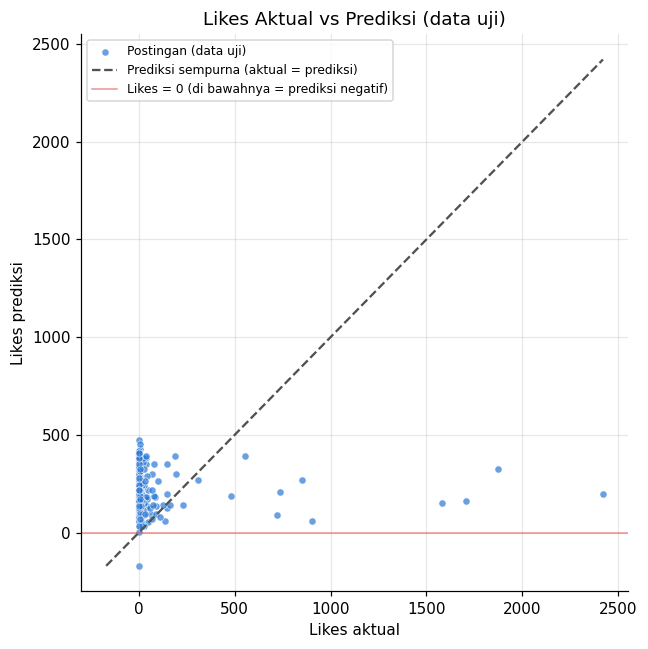

In [35]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, s=22, alpha=0.7, color='#2a78d6', edgecolors='white', linewidths=0.5,
           label='Postingan (data uji)')
batas = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax.plot(batas, batas, linestyle='--', linewidth=1.5, color='#52514e', label='Prediksi sempurna (aktual = prediksi)')
ax.axhline(0, color='#e34948', linewidth=1, alpha=0.6, label='Likes = 0 (di bawahnya = prediksi negatif)')
ax.set_xlabel('Likes aktual')
ax.set_ylabel('Likes prediksi')
ax.set_title('Likes Aktual vs Prediksi (data uji)')
ax.legend(fontsize=8)
# Kalau ada satu-dua postingan viral sehingga titik lain menumpuk di pojok, aktifkan baris berikut:
# ax.set_xscale('symlog'); ax.set_yscale('symlog')
plt.tight_layout()
plt.show()

hasil_regresi = X_test.copy()
hasil_regresi['like_aktual'] = y_test
hasil_regresi['like_prediksi'] = y_pred.round(2)
hasil_regresi.to_csv(os.path.join(FOLDER_OUT, 'hasil_regresi_data_uji.csv'), index=False)

RINGKASAN ANGKA UNTUK TEMUAN DAN KETERBATASAN



In [36]:
# pembanding sederhana
print('Median likes data uji:', y_test.median())
print('MAE tebak median     :', round(mean_absolute_error(y_test, np.full(len(y_test), y_train.median())), 2))
print('MAE tebak rata-rata  :', round(mae_pembanding, 2))

# lima postingan dengan selisih terbesar (bahan keterbatasan)
sel = X_test[['jumlah_kata', 'jumlah_hashtag']].copy()
sel['aktual'] = y_test; sel['prediksi'] = y_pred.round(1)
sel['selisih'] = (sel['aktual'] - sel['prediksi']).abs()
display(sel.sort_values('selisih', ascending=False).head(5))

Median likes data uji: 5.0
MAE tebak median     : 62.54
MAE tebak rata-rata  : 209.6


,jumlah_kata,jumlah_hashtag,aktual,prediksi,selisih
453,34,0,2421,198.1,2222.9
435,20,0,1876,325.9,1550.1
1001,38,0,1706,161.5,1544.5
617,39,0,1583,152.4,1430.6
289,49,0,903,61.0,842.0


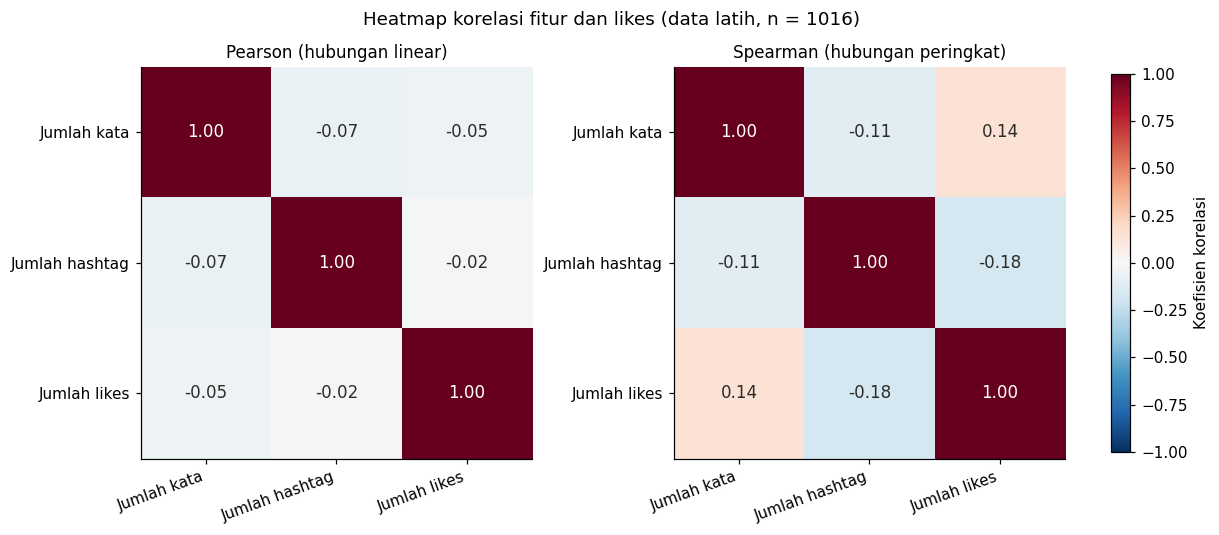

Korelasi dengan likes (data latih):
{'jumlah_kata': -0.054, 'jumlah_hashtag': -0.015} (Pearson)
{'jumlah_kata': 0.143, 'jumlah_hashtag': -0.178} (Spearman)
Postingan dengan >= 1 hashtag di data latih: 62 dari 1016


In [37]:
data_latih = X_train.copy()
data_latih['like_count'] = y_train
NAMA_KOLOM = {'jumlah_kata': 'Jumlah kata', 'jumlah_hashtag': 'Jumlah hashtag', 'like_count': 'Jumlah likes'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True)
for ax, (metode, judul) in zip(axes, [('pearson', 'Pearson (hubungan linear)'),
                                      ('spearman', 'Spearman (hubungan peringkat)')]):
    korelasi = data_latih.corr(method=metode).rename(index=NAMA_KOLOM, columns=NAMA_KOLOM)
    gambar = ax.imshow(korelasi.values, cmap='RdBu_r', vmin=-1, vmax=1)
    n_kol = len(korelasi)
    ax.set_xticks(range(n_kol)); ax.set_yticks(range(n_kol))
    ax.set_xticklabels(korelasi.columns, rotation=20, ha='right')
    ax.set_yticklabels(korelasi.index)
    for i in range(n_kol):
        for j in range(n_kol):
            nilai = korelasi.values[i, j]
            ax.text(j, i, 'n/a' if np.isnan(nilai) else f'{nilai:.2f}', ha='center', va='center',
                    fontsize=11, color='white' if abs(nilai) > 0.6 else '#2c2c2a')
    ax.set_title(judul, fontsize=11)
    ax.grid(False)
fig.colorbar(gambar, ax=axes, shrink=0.85, label='Koefisien korelasi')
fig.suptitle(f'Heatmap korelasi fitur dan likes (data latih, n = {len(data_latih)})', fontsize=12)
# fig.savefig(os.path.join(FOLDER_OUT, 'heatmap_korelasi.png'), dpi=200, bbox_inches='tight')   # aktifkan untuk laporan
plt.show()

print('Korelasi dengan likes (data latih):')
print(data_latih.corr(method='pearson')['like_count'].drop('like_count').round(3).to_dict(), '(Pearson)')
print(data_latih.corr(method='spearman')['like_count'].drop('like_count').round(3).to_dict(), '(Spearman)')
print(f"Postingan dengan >= 1 hashtag di data latih: {(X_train['jumlah_hashtag'] > 0).sum()} dari {len(X_train)}")

MAE                 : 48.30 likes
R²                  : 0.673
MAE tebak median    : 62.54 likes
MAE tebak rata-rata : 209.60 likes

likes ≈ 14.60 + (4.959 × retweet) + (8.267 × reply)
Prediksi negatif: 0 dari 254


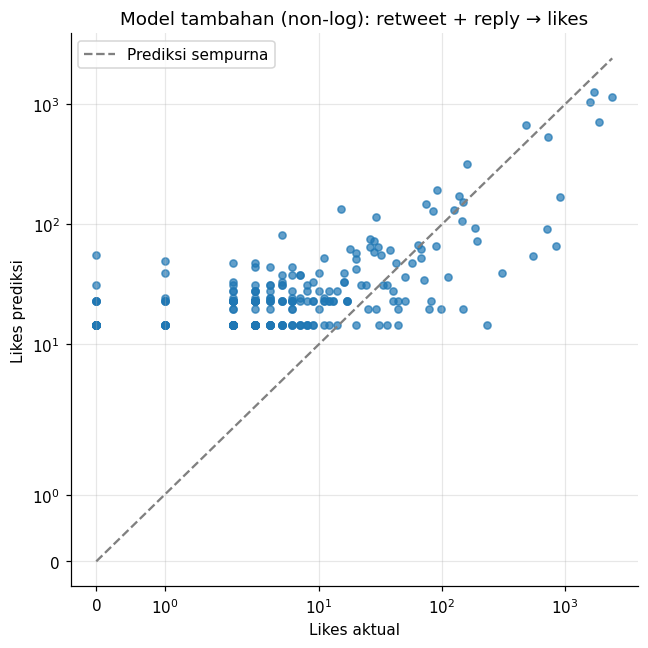

In [38]:
# ===== MODEL TAMBAHAN (NON-LOG): retweet + reply → likes, skala asli =====
FITUR_ENG = ['retweet_count', 'reply_count']
X2 = df[FITUR_ENG]
X2_train, X2_test = X2.loc[X_train.index], X2.loc[X_test.index]   # baris sama dengan model utama

model2 = LinearRegression().fit(X2_train, y_train)   # hanya belajar dari data latih
y_pred2 = model2.predict(X2_test)

mae2 = mean_absolute_error(y_test, y_pred2)
r2_2 = r2_score(y_test, y_pred2)
mae_median = mean_absolute_error(y_test, np.full(len(y_test), y_train.median()))

print(f'MAE                 : {mae2:.2f} likes')
print(f'R²                  : {r2_2:.3f}')
print(f'MAE tebak median    : {mae_median:.2f} likes')
print(f'MAE tebak rata-rata : {mae_pembanding:.2f} likes')
print(f'\nlikes ≈ {model2.intercept_:.2f} + ({model2.coef_[0]:.3f} × retweet) + ({model2.coef_[1]:.3f} × reply)')
print(f'Prediksi negatif: {int((y_pred2 < 0).sum())} dari {len(y_pred2)}')

# grafik aktual vs prediksi
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred2, s=22, alpha=0.7)
batas = max(y_test.max(), y_pred2.max())
ax.plot([0, batas], [0, batas], '--', color='gray', label='Prediksi sempurna')
ax.set_xscale('symlog'); ax.set_yscale('symlog')
ax.set_xlabel('Likes aktual'); ax.set_ylabel('Likes prediksi')
ax.set_title('Model tambahan (non-log): retweet + reply → likes'); ax.legend()
plt.tight_layout(); plt.show()

In [39]:
import json, joblib, sklearn

# 1) parameter model (intersep + koefisien): ini yang dipakai app.py
parameter_model = {
    'model_utama': {'fitur': FITUR, 'intercept': float(model.intercept_),
                    'koefisien': [float(c) for c in model.coef_],
                    'rentang': {k: int(df[k].max()) for k in FITUR},
                    'mae': float(mae), 'r2': float(r2)},
    'model_tambahan': {'fitur': FITUR_ENG, 'intercept': float(model2.intercept_),
                       'koefisien': [float(c) for c in model2.coef_],
                       'rentang': {k: int(df[k].max()) for k in FITUR_ENG},
                       'mae': float(mae2), 'r2': float(r2_2)},
}
path_json = os.path.join(FOLDER_OUT, 'parameter_model.json')
with open(path_json, 'w', encoding='utf-8') as f:
    json.dump(parameter_model, f, indent=2, ensure_ascii=False)

# 2) (opsional) model utuh untuk arsip / dimuat dengan joblib
path_joblib = os.path.join(FOLDER_OUT, 'model_regresi.joblib')
joblib.dump({'utama': model, 'tambahan': model2, 'versi_sklearn': sklearn.__version__}, path_joblib)

print('Versi scikit-learn di Colab:', sklearn.__version__)
print('Tersimpan di Drive:', path_json, '|', path_joblib)
print(json.dumps(parameter_model, indent=2))

# 3) unduh ke komputer
from google.colab import files
files.download(path_json)
files.download(path_joblib)

Versi scikit-learn di Colab: 1.6.1
Tersimpan di Drive: /content/drive/MyDrive/Projek_PAW_Kelompok3/output/parameter_model.json | /content/drive/MyDrive/Projek_PAW_Kelompok3/output/model_regresi.joblib
{
  "model_utama": {
    "fitur": [
      "jumlah_kata",
      "jumlah_hashtag"
    ],
    "intercept": 508.6111624137541,
    "koefisien": [
      -9.13399705039907,
      -45.9493404147147
    ],
    "rentang": {
      "jumlah_kata": 58,
      "jumlah_hashtag": 14
    },
    "mae": 217.9109321696503,
    "r2": -0.4487370396970294
  },
  "model_tambahan": {
    "fitur": [
      "retweet_count",
      "reply_count"
    ],
    "intercept": 14.599969338252947,
    "koefisien": [
      4.959438265881986,
      8.266765137713044
    ],
    "rentang": {
      "retweet_count": 8534,
      "reply_count": 109
    },
    "mae": 48.2966015919912,
    "r2": 0.6726593224943087
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
kolom_app = ['id', 'created_at', 'text', 'text_clean', 'like_count', 'retweet_count', 'reply_count',
             'lang', 'query', 'sentimen', 'skor_sentimen', 'ragu', 'cluster', 'tema',
             'jumlah_kata', 'jumlah_hashtag']
df[[k for k in kolom_app if k in df.columns]].to_csv(os.path.join(FOLDER_OUT, 'dataset_hasil.csv'), index=False)
ringkasan_cluster.to_csv(os.path.join(FOLDER_OUT, 'ringkasan_cluster.csv'), index=False)

print('Rentang aktual:', df['created_at'].min(), 's.d.', df['created_at'].max())
print(df['query'].value_counts())
display(tabel_tahap)

Rentang aktual: 2025-01-10 09:50:03+07:00 s.d. 2026-10-11 23:05:59+07:00
query
seniman ai       264
ilustrator ai    253
hak cipta ai     241
penulis ai       230
desainer ai      194
musisi ai         88
Name: count, dtype: int64


,Tahap,Jumlah data,Berkurang,Keterangan
0,1. Data mentah (gabungan semua query),1720,0,6 file query
1,2. Buang duplikat,1686,34,berdasarkan kolom id
2,3. Saring bahasa,1622,64,lang = 'in' (Bahasa Indonesia)
3,4. Saring periode,1490,132,2025-01-01 s.d. 2026-10-11
4,5. Saring relevansi,1287,203,memuat kata AI dan kata profesi kreatif
5,6. Buang promosi,1286,1,frasa kuat (semua) + frasa lemah (non-balasan)
6,7. Buang teks kosong,1286,0,
7,8. Buang likes tidak valid,1286,0,"kosong/bukan angka/negatif dibuang, tidak diga..."
8,9. Buang yang kosong setelah dibersihkan,1286,0,
9,10. Buang duplikat isi,1276,10,text_clean sama / 80 karakter awal sama
